# ANLY 530 | Food Demand Forecasting: Milestone 1
**Purpose:** audit the dataset, document the time split, and establish reproducible baselines. No results are fabricated; run all cells on the downloaded CSV.

In [2]:
from pathlib import Path
import shutil

Path("data").mkdir(exist_ok=True)
shutil.copy("/content/train.csv", "data/train.csv")

print("Dataset ready!")

Dataset ready!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone
RANDOM_STATE = 42
DATA = next((p for p in [Path("data/train.csv"), Path("../data/train.csv")] if p.exists()), Path("data/train.csv"))
assert DATA.exists(), "Download train.csv and put it in data/train.csv"
df = pd.read_csv(DATA)
print(df.shape); display(df.head())

(456548, 9)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


Missing values:
 id                       0
week                     0
center_id                0
meal_id                  0
checkout_price           0
base_price               0
emailer_for_promotion    0
homepage_featured        0
num_orders               0
dtype: int64
Duplicate week-center-meal keys: 0
Weeks: 1 145


,num_orders
count,456548.000000
mean,261.872760
std,395.922798
min,13.000000
25%,54.000000
50%,136.000000
75%,324.000000
max,24299.000000


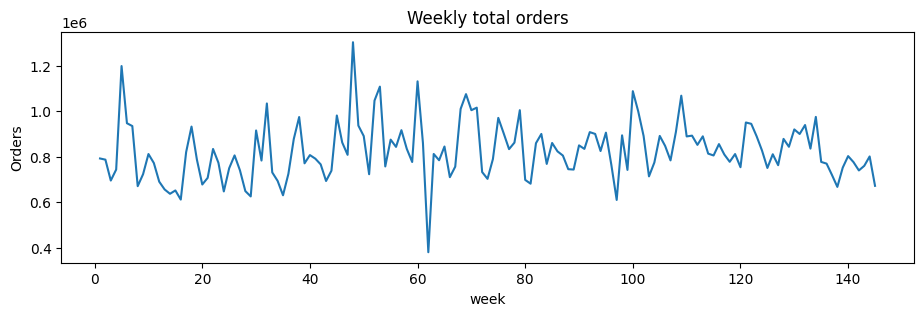

In [4]:
required = {"week","center_id","meal_id","checkout_price","base_price","emailer_for_promotion","homepage_featured","num_orders"}
assert required.issubset(df.columns), f"Missing: {required-set(df.columns)}"
print("Missing values:\n",df.isna().sum())
print("Duplicate week-center-meal keys:",df.duplicated(["week","center_id","meal_id"]).sum())
print("Weeks:",df.week.min(),df.week.max())
display(df.num_orders.describe())
df.groupby("week").num_orders.sum().plot(figsize=(11,3),title="Weekly total orders");plt.ylabel("Orders");plt.show()

## Evaluation assumptions
Prices and promotion indicators are assumed to be known at forecast issuance. No target-derived lag is used. The test period is weeks 117–145, and validation folds are chronological subsets of weeks 1–116.

In [5]:
df=df.sort_values(["week","center_id","meal_id"]).reset_index(drop=True)
train=df[df.week<=116].copy(); test=df[df.week>=117].copy()
print("Development:",train.shape,"Final holdout:",test.shape)
features=["week","center_id","meal_id","checkout_price","base_price","emailer_for_promotion","homepage_featured"]
cat=["center_id","meal_id"];num=[x for x in features if x not in cat]
try:
    encoder=OneHotEncoder(handle_unknown="ignore",sparse_output=True)
except TypeError:
    encoder=OneHotEncoder(handle_unknown="ignore",sparse=True)
prep=ColumnTransformer([("num",Pipeline([("imp",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),("cat",Pipeline([("imp",SimpleImputer(strategy="most_frequent")),("ohe",encoder)]),cat)])
models={"Linear regression":LinearRegression(),"Ridge":Ridge(alpha=10.0),"Lasso":Lasso(alpha=0.1,max_iter=3000)}

Development: (361348, 9) Final holdout: (95200, 9)


In [6]:
def folds(data, initial=56, block=12):
    weeks=np.sort(data.week.unique())
    for end in range(initial,len(weeks),block):
        valid=weeks[end:min(end+block,len(weeks))]
        if len(valid)==0:continue
        yield data.week.isin(weeks[:end]).to_numpy(),data.week.isin(valid).to_numpy(),int(valid.min()),int(valid.max())

def historical_predict(history, future):
    avg=history.groupby(["center_id","meal_id"]).num_orders.mean()
    keys=pd.MultiIndex.from_frame(future[["center_id","meal_id"]])
    pred=avg.reindex(keys).to_numpy()
    return np.where(np.isnan(pred),history.num_orders.mean(),pred)

rows=[]
for mask_tr,mask_val,start,end in folds(train):
    tr=train.loc[mask_tr];va=train.loc[mask_val]
    for name in ["Historical mean",*models]:
        if name=="Historical mean":pred=historical_predict(tr,va)
        else:
            pipe=Pipeline([("prep",clone(prep)),("model",clone(models[name]))])
            pipe.fit(tr[features],tr.num_orders)
            pred=pipe.predict(va[features])
        pred=np.maximum(0,pred)
        rows.append({"model":name,"start_week":start,"end_week":end,"mae":mean_absolute_error(va.num_orders,pred),"rmse":np.sqrt(mean_squared_error(va.num_orders,pred))})
cv=pd.DataFrame(rows)
display(cv.groupby("model")[["mae","rmse"]].agg(["mean","std"]).round(2))

mae          rmse       
                     mean   std    mean    std
model                                         
Historical mean    120.76  7.69  270.10  40.39
Lasso              144.62  2.73  269.58  32.70
Linear regression  144.72  2.90  268.72  32.81
Ridge              144.67  2.89  268.74  32.82

In [7]:
summary=cv.groupby("model").mae.mean().sort_values()
selected=summary.index[0]
print("Selected by development CV:",selected)
if selected=="Historical mean":pred=historical_predict(train,test)
else:
    final=Pipeline([("prep",clone(prep)),("model",clone(models[selected]))])
    final.fit(train[features],train.num_orders)
    pred=final.predict(test[features])
pred=np.maximum(0,pred)
print("Holdout MAE:",round(mean_absolute_error(test.num_orders,pred),2))
print("Holdout RMSE:",round(np.sqrt(mean_squared_error(test.num_orders,pred)),2))
print("Holdout bias:",round(np.mean(pred-test.num_orders),2))

Selected by development CV: Historical mean
Holdout MAE: 109.84
Holdout RMSE: 249.01
Holdout bias: 12.86


In [8]:
from pathlib import Path
out=Path("results") if Path("data").exists() else Path("../results");out.mkdir(exist_ok=True)
cv.to_csv(out/"chronological_cv.csv",index=False)
pd.DataFrame({"week":test.week,"actual":test.num_orders,"predicted":pred}).to_csv(out/"holdout_predictions.csv",index=False)
print("Saved outputs to",out)

Saved outputs to results
